# Vendor & Spatial Data Analysis
## Pemetaan Vendor Kudus Dandangan Festival 2025


## 1. Import libraries and load dataset


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
from pathlib import Path
import io

# Upload file Excel dari komputer
uploaded = files.upload()

# Mengambil nama file yang di-upload
file_name = next(iter(uploaded))

# Membaca file Excel
df_raw = pd.read_excel(
    io.BytesIO(uploaded[file_name]),
    sheet_name="Data_Vendor"
)

# Membuat salinan dataset
df = df_raw.copy()

print(f"Dataset berhasil dimuat: {df.shape[0]:,} baris × {df.shape[1]} kolom")

# Menampilkan 5 data pertama
display(df.head())

Saving Data_Pemetaan_Dandangan_950.xlsx to Data_Pemetaan_Dandangan_950.xlsx
Dataset berhasil dimuat: 950 baris × 17 kolom


,ID_Vendor,Nama_Usaha,Kategori,Jenis_Dagangan,Kecamatan_Asal,Zona,No_Lapak,Ukuran_Lapak_m2,Status_Retribusi,Tanggal_Pendaftaran,Tanggal_Validasi,Status_Validasi,Jenis_Ketidaksesuaian,Event,Latitude,Longitude,Koordinat
0,VND-0001,Kue Tradisi 96,Makanan,Jajanan,Kota,Zona E,E-041,3,Sudah lunas,2025-02-03,2025-02-06,Sesuai,NaN,Kudus Dandangan 2025,-6.807100,110.839665,"-6.8071,110.839665"
1,VND-0002,Gorengan Renyah 01,Makanan,Gorengan,Jekulo,Zona C,C-090,2,Sudah lunas,2025-02-10,2025-02-15,Sesuai,NaN,Kudus Dandangan 2025,-6.806076,110.836365,"-6.806076,110.836365"
2,VND-0003,Wedang Hangat 62,Minuman,Wedang/Minuman hangat,Undaan,Zona F,F-142,3,Sudah lunas,2025-02-11,2025-02-15,Sesuai,NaN,Kudus Dandangan 2025,-6.807525,110.840653,"-6.807525,110.840653"
3,VND-0004,Sate Rasa Kudus 09,Makanan,Sate,Undaan,Zona D,D-053,4,Sudah lunas,2025-02-16,2025-02-17,Sesuai,NaN,Kudus Dandangan 2025,-6.806308,110.838027,"-6.806308,110.838027"
4,VND-0005,Toko Rumah 98,Perlengkapan Rumah,Perlengkapan rumah,Undaan,Zona C,C-117,2,Sudah lunas,2025-02-15,2025-02-18,Sesuai,NaN,Kudus Dandangan 2025,-6.805552,110.836563,"-6.805552,110.836563"


## 2. Data understanding


In [ ]:
print("DIMENSI DATA:", df.shape)
print("\\nTIPE DATA")
display(df.dtypes.rename("data_type").to_frame())
print("\\nRINGKASAN NUMERIK")
display(df.describe().T)
print("\\nRINGKASAN KATEGORIK")
display(df.describe(include="object").T)

DIMENSI DATA: (950, 17)
\nTIPE DATA


,data_type
ID_Vendor,object
Nama_Usaha,object
Kategori,object
Jenis_Dagangan,object
Kecamatan_Asal,object
Zona,object
No_Lapak,object
Ukuran_Lapak_m2,int64
Status_Retribusi,object
Tanggal_Pendaftaran,datetime64[ns]


\nRINGKASAN NUMERIK


,count,mean,min,25%,50%,75%,max,std
Ukuran_Lapak_m2,950.0,5.057895,2.0,3.0,4.0,6.0,12.0,2.634339
Tanggal_Pendaftaran,950,2025-02-09 08:50:31.578947328,2025-02-03 00:00:00,2025-02-06 00:00:00,2025-02-09 00:00:00,2025-02-13 00:00:00,2025-02-16 00:00:00,NaN
Tanggal_Validasi,950,2025-02-12 13:33:58.736842240,2025-02-04 00:00:00,2025-02-09 00:00:00,2025-02-12 00:00:00,2025-02-16 00:00:00,2025-02-24 00:00:00,NaN
Latitude,950.0,-6.805986,-6.807594,-6.80676,-6.806041,-6.805142,-6.804401,0.000914
Longitude,950.0,110.83685,110.832321,110.834345,110.836652,110.839327,110.841598,0.002803


\nRINGKASAN KATEGORIK


,count,unique,top,freq
ID_Vendor,950,950,VND-0001,1
Nama_Usaha,950,862,Mie Ayam Sederhana 18,4
Kategori,950,7,Makanan,343
Jenis_Dagangan,950,22,Bakso/Mie,82
Kecamatan_Asal,950,9,Kota,202
Zona,950,6,Zona A,170
No_Lapak,950,950,E-041,1
Status_Retribusi,950,2,Sudah lunas,838
Status_Validasi,950,2,Sesuai,920
Jenis_Ketidaksesuaian,30,4,Nama usaha tidak sesuai,12


## 3. Data quality assessment


In [ ]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality.sort_values("missing_count", ascending=False))

print("Duplikasi seluruh baris:", df.duplicated().sum())
print("Duplikasi ID vendor:", df["ID_Vendor"].duplicated().sum())
print("Duplikasi nomor lapak:", df["No_Lapak"].duplicated().sum())
print("Duplikasi nama usaha:", df["Nama_Usaha"].duplicated().sum(),
      "(perlu ditinjau; nama sama belum tentu entitas yang sama)")

# Validasi logis dan geografis
checks = {
    "Tanggal validasi sebelum pendaftaran":
        (df["Tanggal_Validasi"] < df["Tanggal_Pendaftaran"]).sum(),
    "Ukuran lapak <= 0": (df["Ukuran_Lapak_m2"] <= 0).sum(),
    "Latitude di luar rentang geografis": (~df["Latitude"].between(-90, 90)).sum(),
    "Longitude di luar rentang geografis": (~df["Longitude"].between(-180, 180)).sum(),
    "Koordinat kosong": df[["Latitude", "Longitude"]].isna().any(axis=1).sum()
}
display(pd.Series(checks, name="jumlah_temuan").to_frame())

,missing_count,missing_pct,unique_values
Jenis_Ketidaksesuaian,920,96.84,4
ID_Vendor,0,0.00,950
Nama_Usaha,0,0.00,862
Jenis_Dagangan,0,0.00,22
Kategori,0,0.00,7
Zona,0,0.00,6
No_Lapak,0,0.00,950
Ukuran_Lapak_m2,0,0.00,6
Kecamatan_Asal,0,0.00,9
Status_Retribusi,0,0.00,2


Duplikasi seluruh baris: 0
Duplikasi ID vendor: 0
Duplikasi nomor lapak: 0
Duplikasi nama usaha: 88 (perlu ditinjau; nama sama belum tentu entitas yang sama)


,jumlah_temuan
Tanggal validasi sebelum pendaftaran,0
Ukuran lapak <= 0,0
Latitude di luar rentang geografis,0
Longitude di luar rentang geografis,0
Koordinat kosong,0


### Data preparation


In [ ]:
df["Lama_Validasi_Hari"] = (
    df["Tanggal_Validasi"] - df["Tanggal_Pendaftaran"]
).dt.days
df["Bulan_Pendaftaran"] = df["Tanggal_Pendaftaran"].dt.to_period("M").astype(str)

# Normalisasi label teks untuk mengurangi variasi spasi tanpa mengubah makna kategori.
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()

print("Data siap dianalisis:", df.shape)
display(df[["ID_Vendor", "Tanggal_Pendaftaran", "Tanggal_Validasi",
            "Lama_Validasi_Hari"]].head())

Data siap dianalisis: (950, 19)


,ID_Vendor,Tanggal_Pendaftaran,Tanggal_Validasi,Lama_Validasi_Hari
0,VND-0001,2025-02-03,2025-02-06,3
1,VND-0002,2025-02-10,2025-02-15,5
2,VND-0003,2025-02-11,2025-02-15,4
3,VND-0004,2025-02-16,2025-02-17,1
4,VND-0005,2025-02-15,2025-02-18,3


## 4. Key performance indicators (KPI)
KPI ringkas untuk menggambarkan skala dan status operasional vendor.

In [ ]:
n_vendor = len(df)
paid = df["Status_Retribusi"].eq("Sudah lunas").sum()
validated = df["Status_Validasi"].eq("Sesuai").sum()
corrected = df["Status_Validasi"].eq("Dikoreksi").sum()
total_area = df["Ukuran_Lapak_m2"].sum()

kpi = pd.DataFrame({
    "Indikator": ["Total vendor", "Retribusi lunas", "Retribusi belum lunas",
                  "Validasi sesuai", "Vendor dikoreksi", "Total luas lapak (m²)",
                  "Rata-rata waktu validasi (hari)"],
    "Nilai": [n_vendor, paid, n_vendor-paid, validated, corrected,
              total_area, df["Lama_Validasi_Hari"].mean()]
})
display(kpi)
print(f"Tingkat pelunasan: {paid/n_vendor:.1%}")
print(f"Tingkat validasi sesuai: {validated/n_vendor:.1%}")

,Indikator,Nilai
0,Total vendor,950.000000
1,Retribusi lunas,838.000000
2,Retribusi belum lunas,112.000000
3,Validasi sesuai,920.000000
4,Vendor dikoreksi,30.000000
5,Total luas lapak (m²),4805.000000
6,Rata-rata waktu validasi (hari),3.196842


Tingkat pelunasan: 88.2%
Tingkat validasi sesuai: 96.8%


## 5. Vendor profile and merchandise mix
Menganalisis kategori dan jenis dagangan untuk melihat komposisi usaha yang mendominasi event.

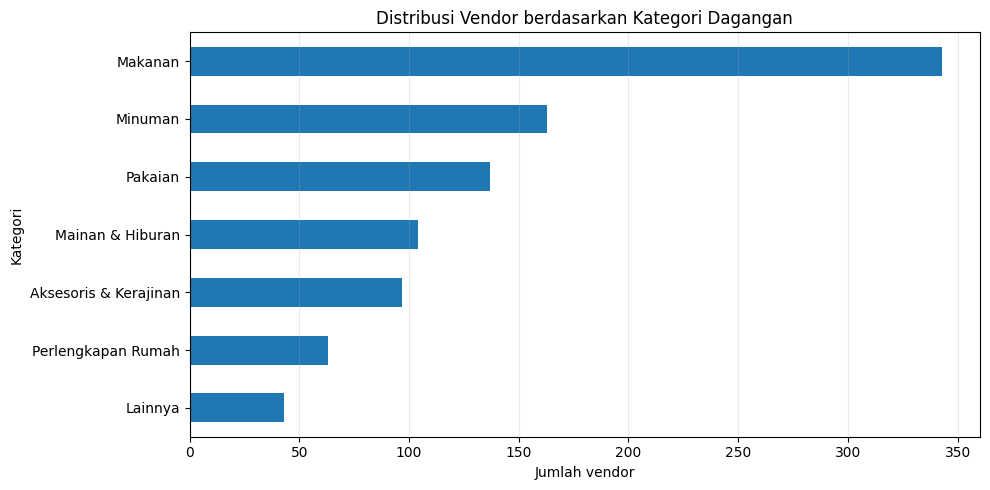

,Jumlah_Vendor
Kategori,
Makanan,343
Minuman,163
Pakaian,137
Mainan & Hiburan,104
Aksesoris & Kerajinan,97
Perlengkapan Rumah,63
Lainnya,43


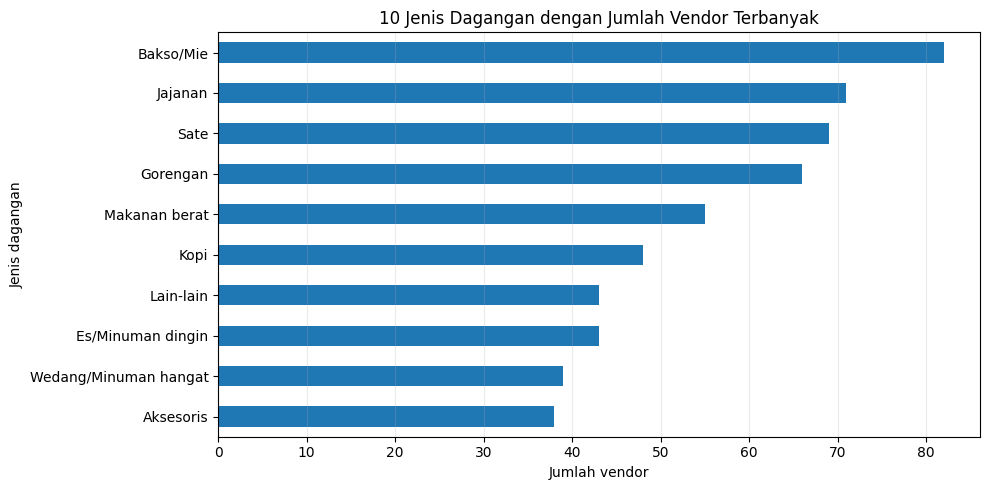

In [ ]:
category_count = df["Kategori"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
category_count.plot(kind="barh", ax=ax)
ax.set_title("Distribusi Vendor berdasarkan Kategori Dagangan")
ax.set_xlabel("Jumlah vendor")
ax.set_ylabel("Kategori")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

display(df["Kategori"].value_counts().rename_axis("Kategori").to_frame("Jumlah_Vendor"))

top_merch = df["Jenis_Dagangan"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
top_merch.plot(kind="barh", ax=ax)
ax.set_title("10 Jenis Dagangan dengan Jumlah Vendor Terbanyak")
ax.set_xlabel("Jumlah vendor")
ax.set_ylabel("Jenis dagangan")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

## 6. Geographic and zone distribution
Membandingkan jumlah vendor menurut zona lapak dan kecamatan asal. Kecamatan asal menunjukkan asal vendor, bukan lokasi domisili pelanggan.

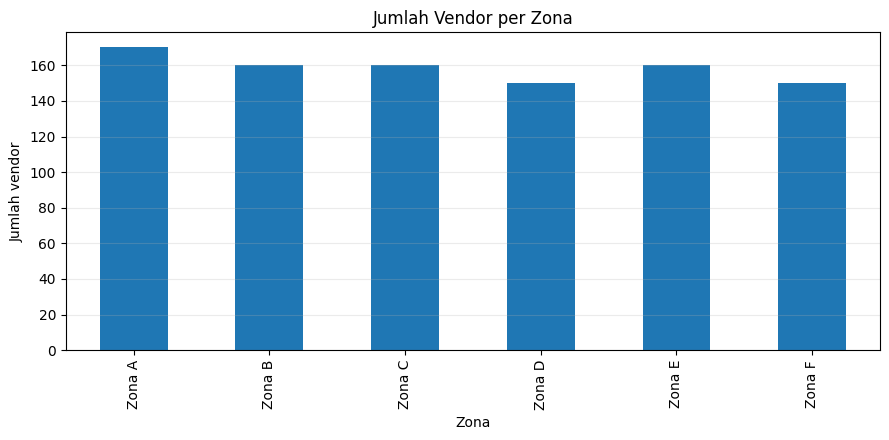

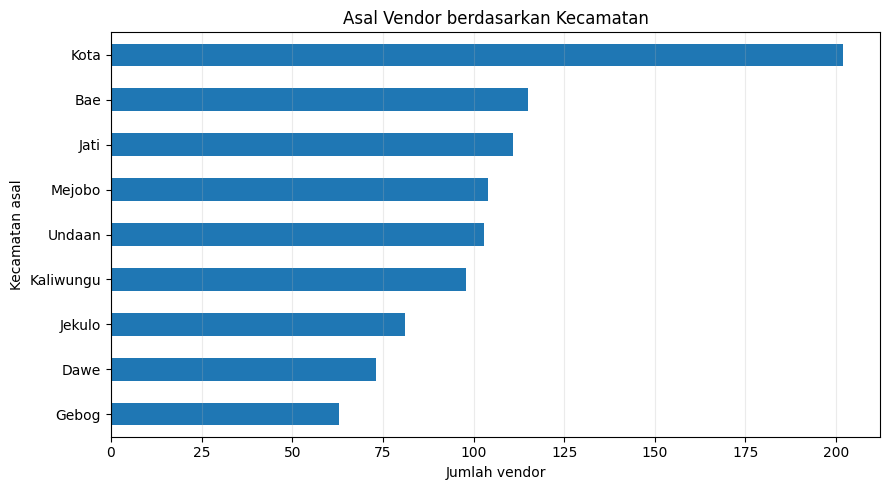

Kategori,Aksesoris & Kerajinan,Lainnya,Mainan & Hiburan,Makanan,Minuman,Pakaian,Perlengkapan Rumah,All
Zona,,,,,,,,
Zona A,17,7,21,60,28,30,7,170
Zona B,18,8,24,41,31,23,15,160
Zona C,16,7,16,58,26,27,10,160
Zona D,17,8,9,63,27,16,10,150
Zona E,19,6,18,61,24,20,12,160
Zona F,10,7,16,60,27,21,9,150
All,97,43,104,343,163,137,63,950


In [ ]:
zone_order = sorted(df["Zona"].unique())
zone_count = df["Zona"].value_counts().reindex(zone_order)
fig, ax = plt.subplots(figsize=(9, 4.5))
zone_count.plot(kind="bar", ax=ax)
ax.set_title("Jumlah Vendor per Zona")
ax.set_xlabel("Zona")
ax.set_ylabel("Jumlah vendor")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

district = df["Kecamatan_Asal"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
district.plot(kind="barh", ax=ax)
ax.set_title("Asal Vendor berdasarkan Kecamatan")
ax.set_xlabel("Jumlah vendor")
ax.set_ylabel("Kecamatan asal")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

display(pd.crosstab(df["Zona"], df["Kategori"], margins=True))

### Spatial scatter plot
Koordinat divisualisasikan sebagai titik longitude-latitude dan diberi warna berdasarkan zona. Plot ini menunjukkan pola persebaran relatif; tanpa peta dasar atau batas zona resmi, visualisasi tidak dapat digunakan untuk memastikan batas administratif atau ketepatan posisi lapak.

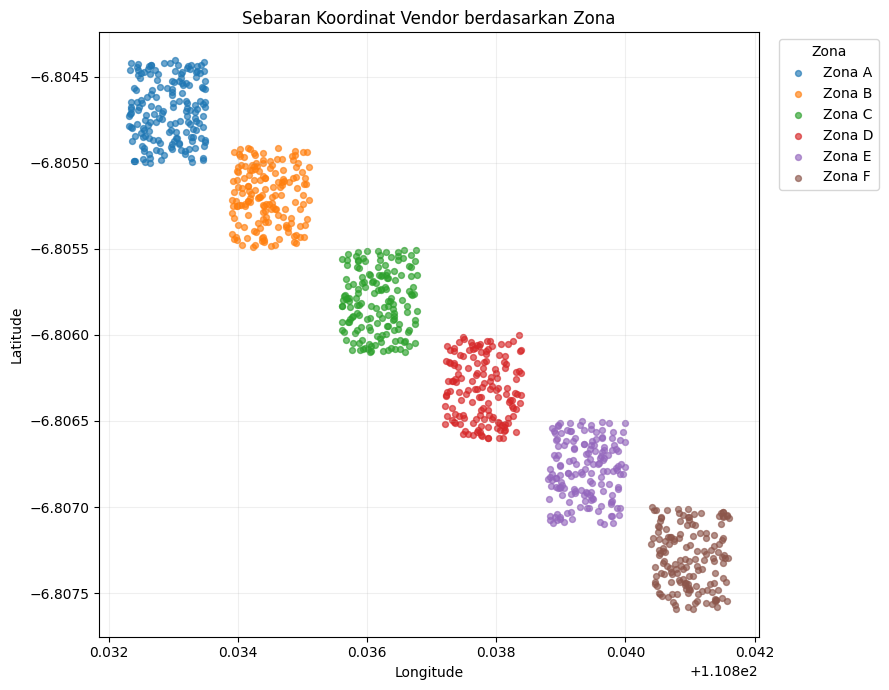

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
for zone, part in df.groupby("Zona"):
    ax.scatter(part["Longitude"], part["Latitude"], s=18, alpha=.65, label=zone)
ax.set_title("Sebaran Koordinat Vendor berdasarkan Zona")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Zona", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 7. Retribution analysis
Mengukur tingkat pelunasan dan melihat distribusinya menurut zona. Data yang tersedia hanya berisi status pembayaran, bukan nominal retribusi, sehingga nilai penerimaan tidak dapat dihitung.

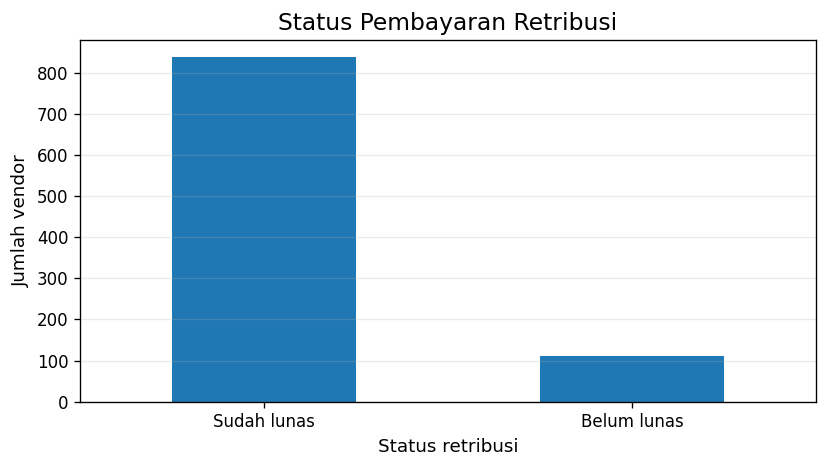

Status_Retribusi,Belum lunas,Sudah lunas,Persen_Belum_Lunas
Zona,,,
Zona A,19,151,11.18
Zona B,14,146,8.75
Zona C,21,139,13.12
Zona D,20,130,13.33
Zona E,20,140,12.50
Zona F,18,132,12.00


In [ ]:
retribusi = df["Status_Retribusi"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
retribusi.plot(kind="bar", ax=ax)
ax.set_title("Status Pembayaran Retribusi")
ax.set_xlabel("Status retribusi")
ax.set_ylabel("Jumlah vendor")
ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

retribusi_zone = pd.crosstab(df["Zona"], df["Status_Retribusi"])
retribusi_zone["Persen_Belum_Lunas"] = (
    retribusi_zone["Belum lunas"] / retribusi_zone.sum(axis=1) * 100
).round(2)
display(retribusi_zone)

## 8. Validation and discrepancy analysis
Menganalisis jumlah data sesuai/dikoreksi, jenis ketidaksesuaian, dan lama proses validasi.

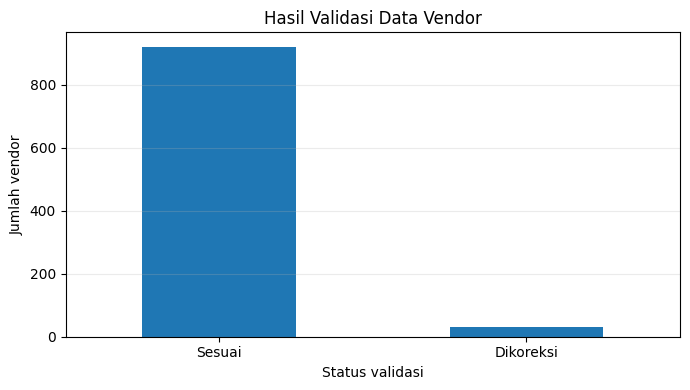

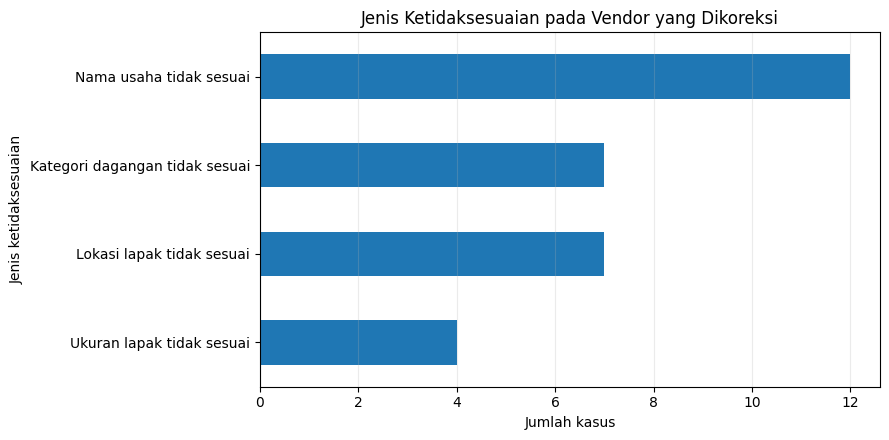

Lama validasi (hari):


,Lama_Validasi_Hari
count,950.000000
mean,3.196842
std,1.697389
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,10.000000


Jumlah vendor dikoreksi per zona:


Status_Validasi,Dikoreksi,Sesuai
Zona,,
Zona A,7,163
Zona B,2,158
Zona C,7,153
Zona D,2,148
Zona E,3,157
Zona F,9,141


In [ ]:
validation = df["Status_Validasi"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
validation.plot(kind="bar", ax=ax)
ax.set_title("Hasil Validasi Data Vendor")
ax.set_xlabel("Status validasi")
ax.set_ylabel("Jumlah vendor")
ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

discrepancy = df["Jenis_Ketidaksesuaian"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5))
discrepancy.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Jenis Ketidaksesuaian pada Vendor yang Dikoreksi")
ax.set_xlabel("Jumlah kasus")
ax.set_ylabel("Jenis ketidaksesuaian")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

print("Lama validasi (hari):")
display(df["Lama_Validasi_Hari"].describe().to_frame())
print("Jumlah vendor dikoreksi per zona:")
display(pd.crosstab(df["Zona"], df["Status_Validasi"]))

## 9. Registration and validation timeline
Melihat jumlah pendaftaran dan validasi harian untuk memahami beban proses sepanjang periode pendataan.

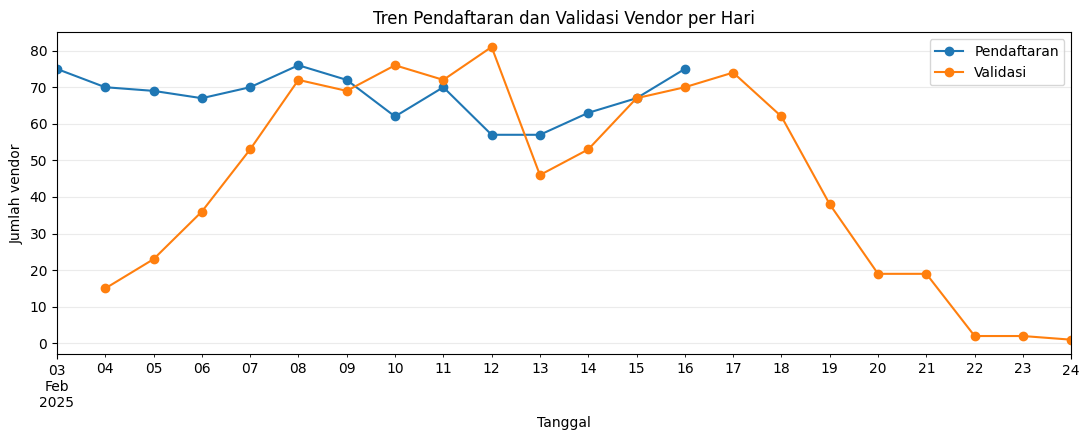

In [ ]:
registration_daily = df.groupby("Tanggal_Pendaftaran").size()
validation_daily = df.groupby("Tanggal_Validasi").size()

fig, ax = plt.subplots(figsize=(11, 4.5))
registration_daily.plot(ax=ax, marker="o", label="Pendaftaran")
validation_daily.plot(ax=ax, marker="o", label="Validasi")
ax.set_title("Tren Pendaftaran dan Validasi Vendor per Hari")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Jumlah vendor")
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 10. Stall area analysis
Mengukur total kebutuhan luas lapak dan membandingkan ukuran lapak antar kategori dagangan.

,Jumlah_Vendor,Total_Luas,Rata_Rata_Luas
Kategori,,,
Makanan,343,1688,4.921283
Minuman,163,779,4.779141
Mainan & Hiburan,104,745,7.163462
Pakaian,137,663,4.839416
Aksesoris & Kerajinan,97,434,4.474227
Perlengkapan Rumah,63,284,4.507937
Lainnya,43,212,4.930233


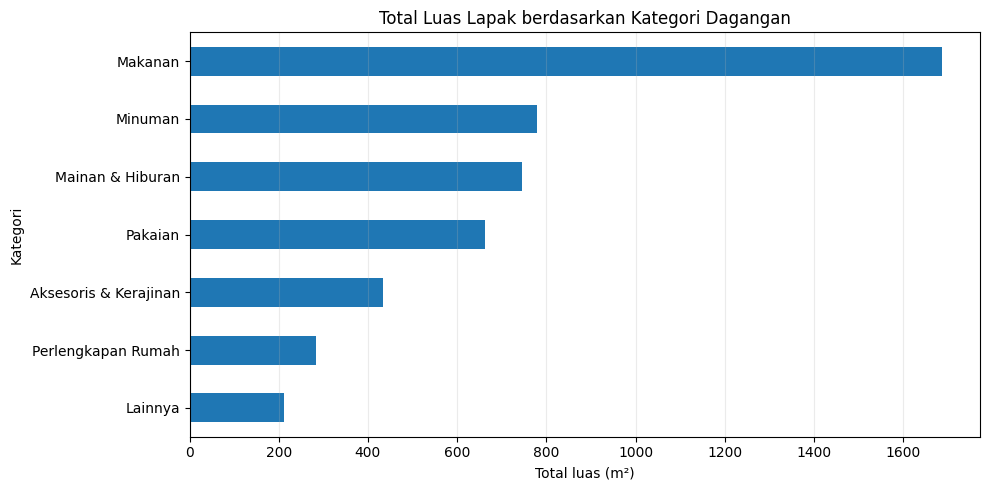

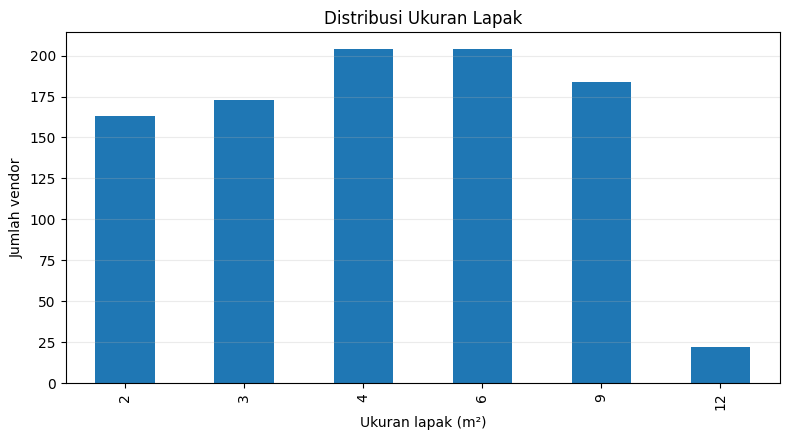

In [ ]:
area_by_category = (df.groupby("Kategori")["Ukuran_Lapak_m2"]
                    .agg(Jumlah_Vendor="count", Total_Luas="sum", Rata_Rata_Luas="mean")
                    .sort_values("Total_Luas", ascending=False))
display(area_by_category)

fig, ax = plt.subplots(figsize=(10, 5))
area_by_category["Total_Luas"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Total Luas Lapak berdasarkan Kategori Dagangan")
ax.set_xlabel("Total luas (m²)")
ax.set_ylabel("Kategori")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
df["Ukuran_Lapak_m2"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Distribusi Ukuran Lapak")
ax.set_xlabel("Ukuran lapak (m²)")
ax.set_ylabel("Jumlah vendor")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

## 11. Key findings
Angka di bawah dihitung langsung dari dataset yang telah dimuat.

In [ ]:
top_category = df["Kategori"].value_counts().idxmax()
top_category_n = df["Kategori"].value_counts().max()
top_district = df["Kecamatan_Asal"].value_counts().idxmax()
top_district_n = df["Kecamatan_Asal"].value_counts().max()
top_zone = df["Zona"].value_counts().idxmax()
top_zone_n = df["Zona"].value_counts().max()
top_discrepancy = df["Jenis_Ketidaksesuaian"].value_counts().idxmax()
top_discrepancy_n = df["Jenis_Ketidaksesuaian"].value_counts().max()
unpaid = df["Status_Retribusi"].eq("Belum lunas").sum()
corrected_rate = df["Status_Validasi"].eq("Dikoreksi").mean()

findings = [
    f"Dataset mencatat {n_vendor:,} vendor yang tersebar pada {df['Zona'].nunique()} zona.",
    f"Kategori terbesar adalah {top_category} sebanyak {top_category_n} vendor ({top_category_n/n_vendor:.1%}).",
    f"Asal vendor terbanyak dari Kecamatan {top_district} sebanyak {top_district_n} vendor ({top_district_n/n_vendor:.1%}).",
    f"{top_zone} memiliki jumlah vendor terbanyak, yaitu {top_zone_n} vendor.",
    f"Sebanyak {paid:,} vendor ({paid/n_vendor:.1%}) berstatus sudah lunas; {unpaid:,} vendor belum lunas.",
    f"{validated:,} vendor ({validated/n_vendor:.1%}) berstatus sesuai dan {corrected:,} vendor ({corrected_rate:.1%}) dikoreksi.",
    f"Jenis ketidaksesuaian terbanyak adalah '{top_discrepancy}' ({top_discrepancy_n} kasus).",
    f"Total luas lapak tercatat {total_area:,} m² dengan rata-rata {df['Ukuran_Lapak_m2'].mean():.2f} m² per vendor.",
    f"Rata-rata jeda pendaftaran ke validasi adalah {df['Lama_Validasi_Hari'].mean():.2f} hari."
]
for i, item in enumerate(findings, 1):
    print(f"{i}. {item}")

1. Dataset mencatat 950 vendor yang tersebar pada 6 zona.
2. Kategori terbesar adalah Makanan sebanyak 343 vendor (36.1%).
3. Asal vendor terbanyak dari Kecamatan Kota sebanyak 202 vendor (21.3%).
4. Zona A memiliki jumlah vendor terbanyak, yaitu 170 vendor.
5. Sebanyak 838 vendor (88.2%) berstatus sudah lunas; 112 vendor belum lunas.
6. 920 vendor (96.8%) berstatus sesuai dan 30 vendor (3.2%) dikoreksi.
7. Jenis ketidaksesuaian terbanyak adalah 'Nama usaha tidak sesuai' (12 kasus).
8. Total luas lapak tercatat 4,805 m² dengan rata-rata 5.06 m² per vendor.
9. Rata-rata jeda pendaftaran ke validasi adalah 3.20 hari.


MACHINE LEARNING

VENDOR SEGMENTATION - MACHINE LEARNING
Total records       : 950
Total features      : 24
Preprocessing       : Completed


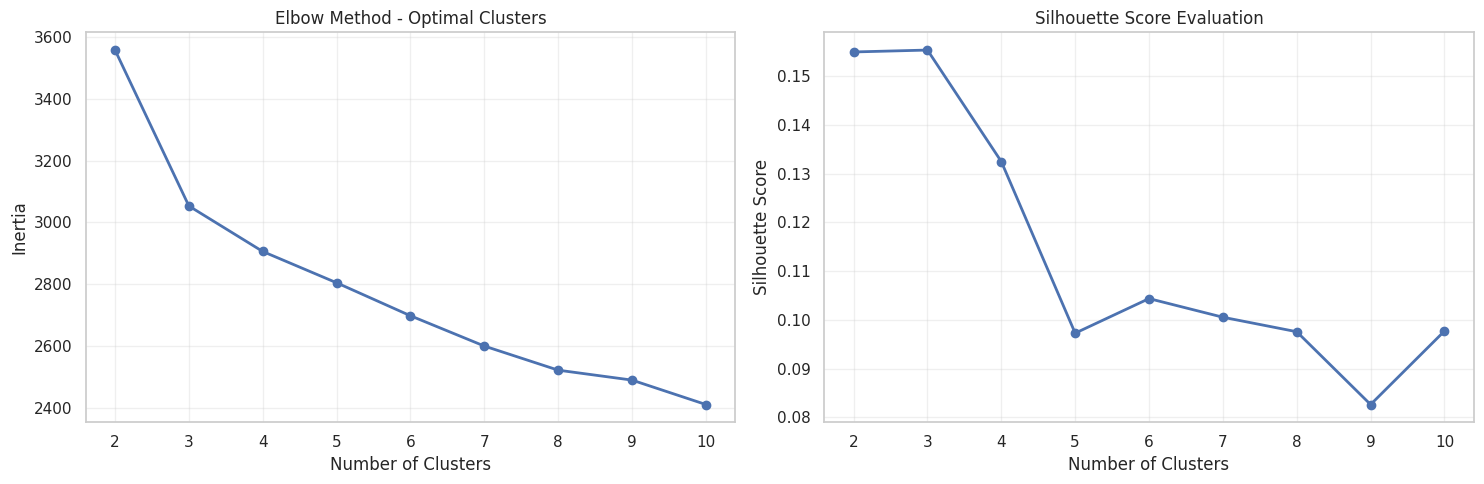


MODEL EVALUATION
---------------------------------------------
Optimal clusters    : 3
Silhouette Score    : 0.1554


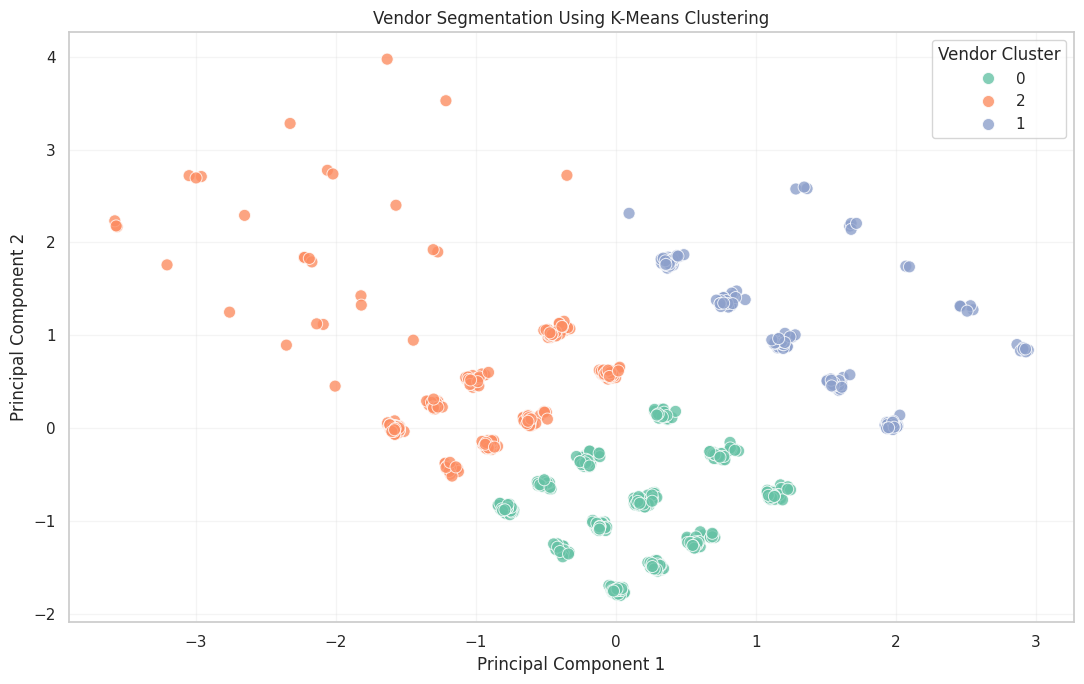

PCA Explained Variance: 44.88%


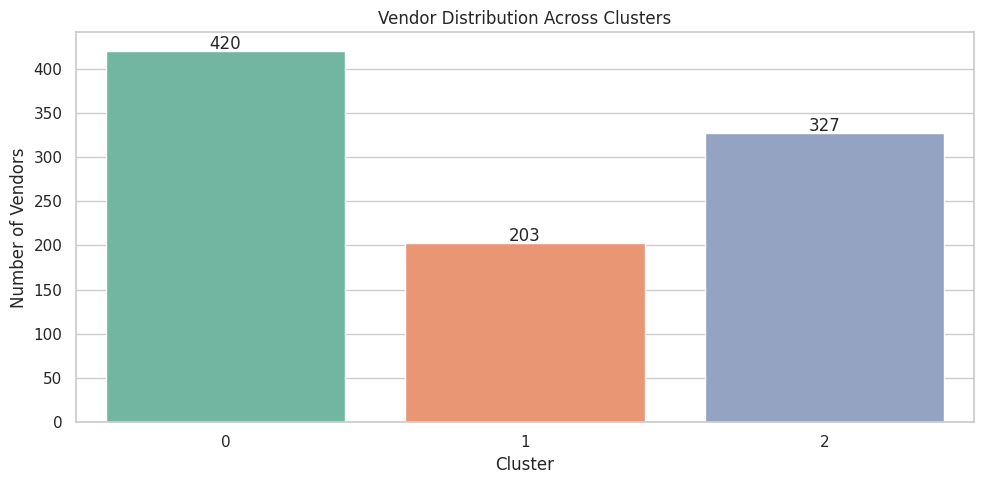


CLUSTER PROFILE


,Total_Vendors,Average_Lapak,Average_Validation_Days,Vendor_Percentage
Vendor_Cluster,,,,
0,420,3.82,1.99,44.21
1,203,9.33,3.01,21.37
2,327,3.99,4.87,34.42


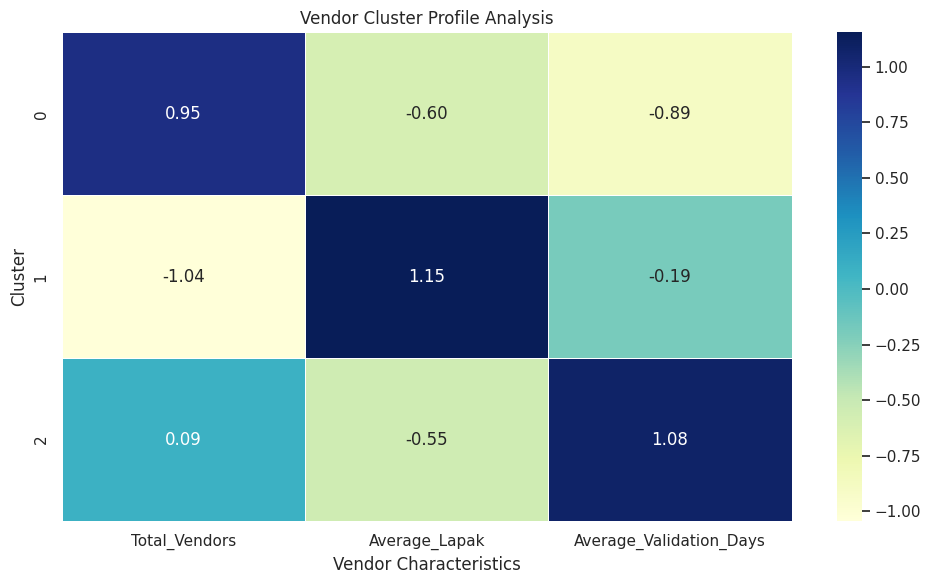


MACHINE LEARNING - BUSINESS INSIGHTS

CLUSTER 0
----------------------------------------
Total Vendors      : 420.0
Vendor Percentage  : 44.21%
Average Stall Area : 3.82 m²
Average Validation : 1.99 days

CLUSTER 1
----------------------------------------
Total Vendors      : 203.0
Vendor Percentage  : 21.37%
Average Stall Area : 9.33 m²
Average Validation : 3.01 days

CLUSTER 2
----------------------------------------
Total Vendors      : 327.0
Vendor Percentage  : 34.42%
Average Stall Area : 3.99 m²
Average Validation : 4.87 days

KEY FINDINGS
Largest segment: Cluster 0 with 420 vendors.
Model Silhouette Score: 0.1554

ANALYSIS COMPLETED SUCCESSFULLY
Vendor results exported : Dandangan_Vendor_Clustering_Results.csv
Cluster profile exported: Dandangan_Cluster_Profile.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# MACHINE LEARNING: VENDOR SEGMENTATION USING K-MEANS
# DANDANGAN FESTIVAL 2025
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. DATA PREPARATION
# ------------------------------------------------------------

features = [
    "Kategori",
    "Kecamatan_Asal",
    "Zona",
    "Ukuran_Lapak_m2",
    "Lama_Validasi_Hari"
]

numeric_features = [
    "Ukuran_Lapak_m2",
    "Lama_Validasi_Hari"
]

categorical_features = [
    "Kategori",
    "Kecamatan_Asal",
    "Zona"
]

df_ml = df[features].copy()

# Preprocessing numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

X = preprocessor.fit_transform(df_ml)

print("=" * 65)
print("VENDOR SEGMENTATION - MACHINE LEARNING")
print("=" * 65)
print(f"Total records       : {len(df_ml):,}")
print(f"Total features      : {X.shape[1]}")
print("Preprocessing       : Completed")

# ------------------------------------------------------------
# 2. OPTIMAL CLUSTER SELECTION
# ------------------------------------------------------------

cluster_range = range(2, min(11, len(df_ml)))
inertia = []
silhouette_scores = []

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

best_k = list(cluster_range)[np.argmax(silhouette_scores)]

# Visualize model evaluation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    list(cluster_range), inertia,
    marker="o", linewidth=2
)
axes[0].set_title("Elbow Method - Optimal Clusters")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    list(cluster_range), silhouette_scores,
    marker="o", linewidth=2
)
axes[1].set_title("Silhouette Score Evaluation")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. TRAIN K-MEANS MODEL
# ------------------------------------------------------------

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Vendor_Cluster"] = kmeans_model.fit_predict(X)

final_silhouette = silhouette_score(
    X,
    df["Vendor_Cluster"]
)

print("\nMODEL EVALUATION")
print("-" * 45)
print(f"Optimal clusters    : {best_k}")
print(f"Silhouette Score    : {final_silhouette:.4f}")

# ------------------------------------------------------------
# 4. PCA CLUSTER VISUALIZATION
# ------------------------------------------------------------

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df["Vendor_Cluster"].astype(str)
})

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=75,
    alpha=0.8
)

plt.title("Vendor Segmentation Using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Vendor Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"PCA Explained Variance: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

# ------------------------------------------------------------
# 5. CLUSTER DISTRIBUTION
# ------------------------------------------------------------

cluster_counts = (
    df["Vendor_Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    hue=cluster_counts.index.astype(str),
    palette="Set2",
    legend=False
)

plt.title("Vendor Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Vendors")

for i, value in enumerate(cluster_counts.values):
    ax.text(i, value + 2, str(value), ha="center")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CLUSTER PROFILING
# ------------------------------------------------------------

cluster_profile = df.groupby("Vendor_Cluster").agg(
    Total_Vendors=("Vendor_Cluster", "count"),
    Average_Lapak=("Ukuran_Lapak_m2", "mean"),
    Average_Validation_Days=("Lama_Validasi_Hari", "mean")
).round(2)

cluster_profile["Vendor_Percentage"] = (
    cluster_profile["Total_Vendors"] / len(df) * 100
).round(2)

print("\nCLUSTER PROFILE")
display(cluster_profile)

# ------------------------------------------------------------
# 7. CLUSTER PROFILE HEATMAP
# ------------------------------------------------------------

profile_features = [
    "Total_Vendors",
    "Average_Lapak",
    "Average_Validation_Days"
]

profile_normalized = cluster_profile[profile_features].copy()

profile_std = profile_normalized.std().replace(0, 1)
profile_normalized = (
    profile_normalized - profile_normalized.mean()
) / profile_std

plt.figure(figsize=(10, 6))

sns.heatmap(
    profile_normalized,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Vendor Cluster Profile Analysis")
plt.xlabel("Vendor Characteristics")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. BUSINESS INSIGHTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MACHINE LEARNING - BUSINESS INSIGHTS")
print("=" * 65)

for cluster_id, row in cluster_profile.iterrows():

    print(f"\nCLUSTER {cluster_id}")
    print("-" * 40)
    print(f"Total Vendors      : {row['Total_Vendors']:,}")
    print(f"Vendor Percentage  : {row['Vendor_Percentage']:.2f}%")
    print(f"Average Stall Area : {row['Average_Lapak']:.2f} m²")
    print(
        f"Average Validation : "
        f"{row['Average_Validation_Days']:.2f} days"
    )

print("\nKEY FINDINGS")
largest_cluster = cluster_profile["Total_Vendors"].idxmax()

print(
    f"Largest segment: Cluster {largest_cluster} "
    f"with {cluster_profile.loc[largest_cluster, 'Total_Vendors']} vendors."
)

print(
    f"Model Silhouette Score: {final_silhouette:.4f}"
)

# ------------------------------------------------------------
# 9. EXPORT MACHINE LEARNING RESULTS
# ------------------------------------------------------------

output_file = "Dandangan_Vendor_Clustering_Results.csv"

df.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

cluster_profile.to_csv(
    "Dandangan_Cluster_Profile.csv",
    encoding="utf-8-sig"
)

print("\n" + "=" * 65)
print("ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 65)
print(f"Vendor results exported : {output_file}")
print("Cluster profile exported: Dandangan_Cluster_Profile.csv")

# Google Colab: download result automatically
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("Run locally: check the output files in your notebook folder.")


## 13. Export analytical dataset
Dataset hasil persiapan dapat diekspor untuk digunakan kembali pada dashboard atau analisis lanjutan.

In [ ]:
output_csv = Path("vendor_dandangan_cleaned.csv")
df.to_csv(output_csv, index=False, encoding="utf-8-sig")
print(f"File hasil cleaning tersimpan: {output_csv.resolve()}")

File hasil cleaning tersimpan: /mnt/data/vendor_dandangan_cleaned.csv
